In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import classification_report, confusion_matrix

# Seed initialization
RANDOM_STATE = 101
tf.random.set_seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)

# Directory configurations
BASE_DIR = './'
TRAIN_PATH = os.path.join(BASE_DIR, 'seg_train/seg_train')
TEST_PATH = os.path.join(BASE_DIR, 'seg_test/seg_test')

categories = sorted([d for d in os.listdir(TRAIN_PATH) if os.path.isdir(os.path.join(TRAIN_PATH, d))])
print(f"Total categories detected: {len(categories)}")
print("Categories:", categories)

# Class balance check
print("\nImage distribution across training sets:")
for category in categories:
    count = len(os.listdir(os.path.join(TRAIN_PATH, category)))
    print(f" • {category.ljust(12)}: {count} images")

Total categories detected: 6
Categories: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']

Image distribution across training sets:
 • buildings   : 2191 images
 • forest      : 2271 images
 • glacier     : 2404 images
 • mountain    : 2512 images
 • sea         : 2274 images
 • street      : 2382 images


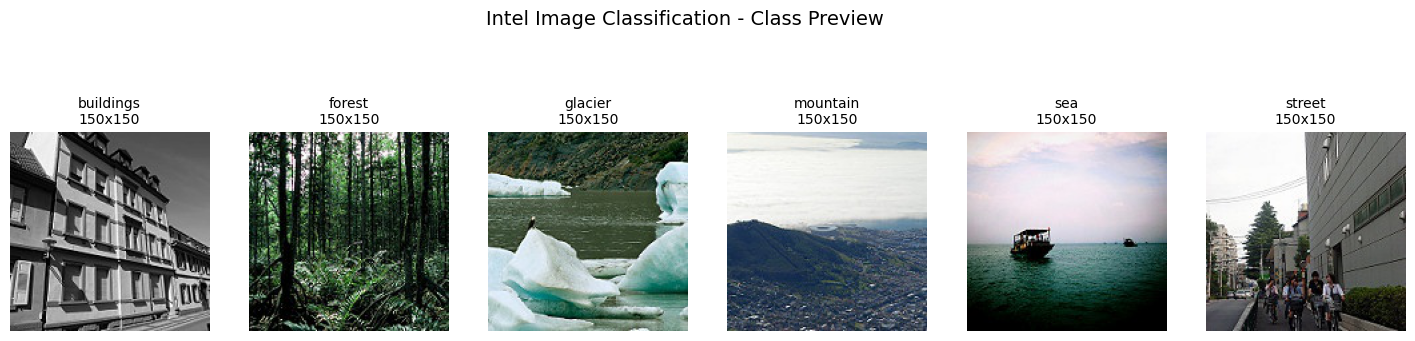

In [2]:
# Preview grid: 1 random sample per category
fig, axes = plt.subplots(1, len(categories), figsize=(18, 4))

for idx, cat in enumerate(categories):
    sample_file = random.choice(os.listdir(os.path.join(TRAIN_PATH, cat)))
    sample_img = Image.open(os.path.join(TRAIN_PATH, cat, sample_file))
    
    axes[idx].imshow(sample_img)
    axes[idx].set_title(f"{cat}\n{sample_img.size[0]}x{sample_img.size[1]}", fontsize=10)
    axes[idx].axis('off')

plt.suptitle("Intel Image Classification - Class Preview", fontsize=14, y=1.05)
plt.show()

In [3]:
TARGET_SIZE = (150, 150)
BATCH = 32

# Load dataset splits (80% train, 20% validation)
raw_train_set = keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="training",
    seed=RANDOM_STATE,
    image_size=TARGET_SIZE,
    batch_size=BATCH,
    label_mode='categorical'
)

raw_val_set = keras.utils.image_dataset_from_directory(
    TRAIN_PATH,
    validation_split=0.2,
    subset="validation",
    seed=RANDOM_STATE,
    image_size=TARGET_SIZE,
    batch_size=BATCH,
    label_mode='categorical'
)

raw_test_set = keras.utils.image_dataset_from_directory(
    TEST_PATH,
    shuffle=False,
    image_size=TARGET_SIZE,
    batch_size=BATCH,
    label_mode='categorical'
)

label_list = raw_train_set.class_names

# Augmentation and rescaling module
augment_pipeline = keras.Sequential([
    layers.Rescaling(1./255),
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1)
], name="augmentation_module")

rescale_only = keras.Sequential([
    layers.Rescaling(1./255)
], name="rescaling_module")

# Streaming dataset optimizations
train_stream = raw_train_set.map(
    lambda x, y: (augment_pipeline(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_stream = raw_val_set.map(
    lambda x, y: (rescale_only(x, training=False), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

test_stream = raw_test_set.map(
    lambda x, y: (rescale_only(x, training=False), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

Found 14034 files belonging to 6 classes.
Using 11228 files for training.
Found 14034 files belonging to 6 classes.
Using 2806 files for validation.
Found 3000 files belonging to 6 classes.


In [4]:
# Model design: 3 distinct conv blocks + pooling + dense regularization
scene_classifier = keras.Sequential([
    layers.Input(shape=(150, 150, 3)),
    
    # Feature Extractor Stage 1
    layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.2),
    
    # Feature Extractor Stage 2
    layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.25),
    
    # Feature Extractor Stage 3
    layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.3),
    
    # Classifier Head using Global Average Pooling
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(len(label_list), activation='softmax')
], name="VGG_Style_Scene_Net")

scene_classifier.summary()

Model: "VGG_Style_Scene_Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 148, 148, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 74, 74, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 72, 72, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 34, 34, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 304,294 (1.16 MB)

 Trainable params: 304,294 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

In [5]:
scene_classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0008),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

run_callbacks = [
    keras.callbacks.ModelCheckpoint(
        'scene_classifier_best.keras',
        monitor='val_accuracy',
        save_best_only=True,
        verbose=1
    ),
    keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True,
        verbose=1
    )
]

TOTAL_EPOCHS = 10

fit_history = scene_classifier.fit(
    train_stream,
    validation_data=val_stream,
    epochs=TOTAL_EPOCHS,
    callbacks=run_callbacks
)

Epoch 1/10


C:\Users\kitch\AppData\Roaming\Python\Python313\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 348ms/step - accuracy: 0.3741 - loss: 1.4420
Epoch 1: val_accuracy improved from None to 0.50036, saving model to scene_classifier_best.keras

Epoch 1: finished saving model to scene_classifier_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 135s 376ms/step - accuracy: 0.3741 - loss: 1.4420 - val_accuracy: 0.5004 - val_loss: 1.1718
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 354ms/step - accuracy: 0.4771 - loss: 1.2283
Epoch 2: val_accuracy improved from 0.50036 to 0.51924, saving model to scene_classifier_best.keras

Epoch 2: finished saving model to scene_classifier_best.keras
351/351 ━━━━━━━━━━━━━━━━━━━━ 134s 380ms/step - accuracy: 0.4771 - loss: 1.2283 - val_accuracy: 0.5192 - val_loss: 1.1116
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 0s 356ms/step - accuracy: 0.5275 - loss: 1.1449
Epoch 3: val_accuracy improved from 0.51924 to 0.58054, saving model to scene_classifier_best.keras

Epoch 3: finished saving model to scene_classifier_best.keras
351/351 ━━━━━━━━━━━

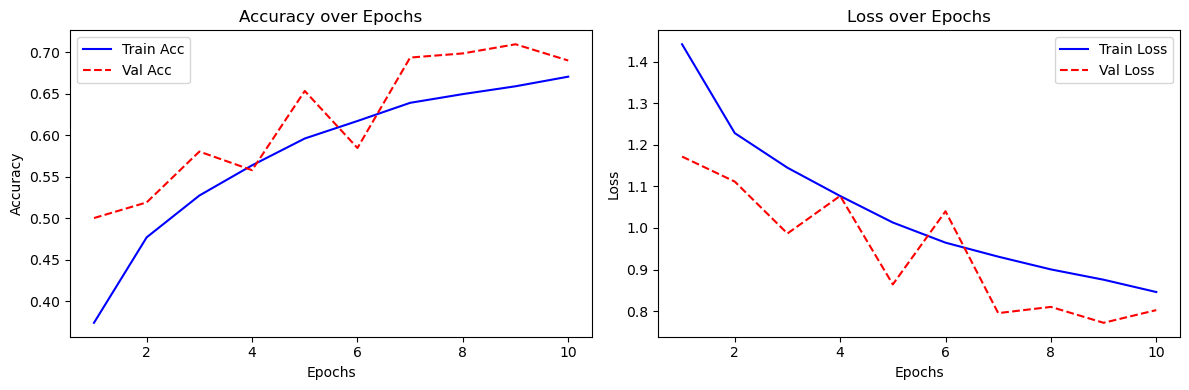

In [6]:
metrics = fit_history.history
epoch_axis = range(1, len(metrics['accuracy']) + 1)

plt.figure(figsize=(12, 4))

# Accuracy tracking
plt.subplot(1, 2, 1)
plt.plot(epoch_axis, metrics['accuracy'], 'b-', label='Train Acc')
plt.plot(epoch_axis, metrics['val_accuracy'], 'r--', label='Val Acc')
plt.title('Accuracy over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Loss tracking
plt.subplot(1, 2, 2)
plt.plot(epoch_axis, metrics['loss'], 'b-', label='Train Loss')
plt.plot(epoch_axis, metrics['val_loss'], 'r--', label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

94/94 ━━━━━━━━━━━━━━━━━━━━ 10s 102ms/step - accuracy: 0.6977 - loss: 0.7600

Test Set Loss:     0.7600
Test Set Accuracy: 69.77%

Classification Report:
              precision    recall  f1-score   support

   buildings       0.70      0.49      0.58       437
      forest       0.88      0.96      0.92       474
     glacier       0.62      0.80      0.70       553
    mountain       0.64      0.71      0.67       525
         sea       0.83      0.44      0.57       510
      street       0.63      0.77      0.70       501

    accuracy                           0.70      3000
   macro avg       0.72      0.69      0.69      3000
weighted avg       0.71      0.70      0.69      3000



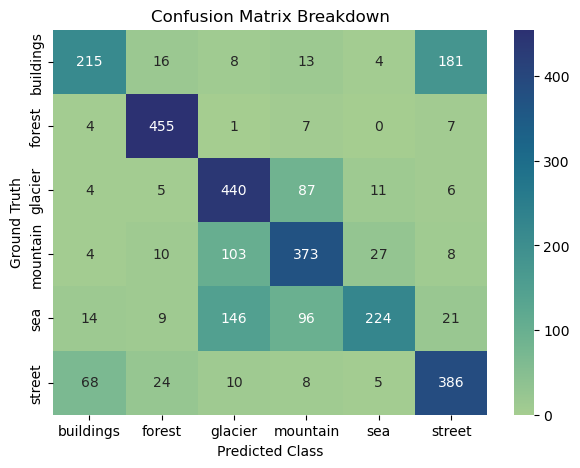

In [7]:
# Overall metrics on the test partition
loss_eval, acc_eval = scene_classifier.evaluate(test_stream)
print(f"\nTest Set Loss:     {loss_eval:.4f}")
print(f"Test Set Accuracy: {acc_eval*100:.2f}%\n")

# Extract ground truths & predictions
true_labels = []
pred_logits = []

for batch_x, batch_y in test_stream:
    preds = scene_classifier.predict(batch_x, verbose=0)
    pred_logits.extend(preds)
    true_labels.extend(np.argmax(batch_y.numpy(), axis=1))

true_labels = np.array(true_labels)
predicted_classes = np.argmax(np.array(pred_logits), axis=1)

# Metrics breakdown per class
print("Classification Report:")
print(classification_report(true_labels, predicted_classes, target_names=label_list))

# Confusion matrix visualization
cm = confusion_matrix(true_labels, predicted_classes)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='g', cmap='crest', xticklabels=label_list, yticklabels=label_list)
plt.xlabel('Predicted Class')
plt.ylabel('Ground Truth')
plt.title('Confusion Matrix Breakdown')
plt.show()

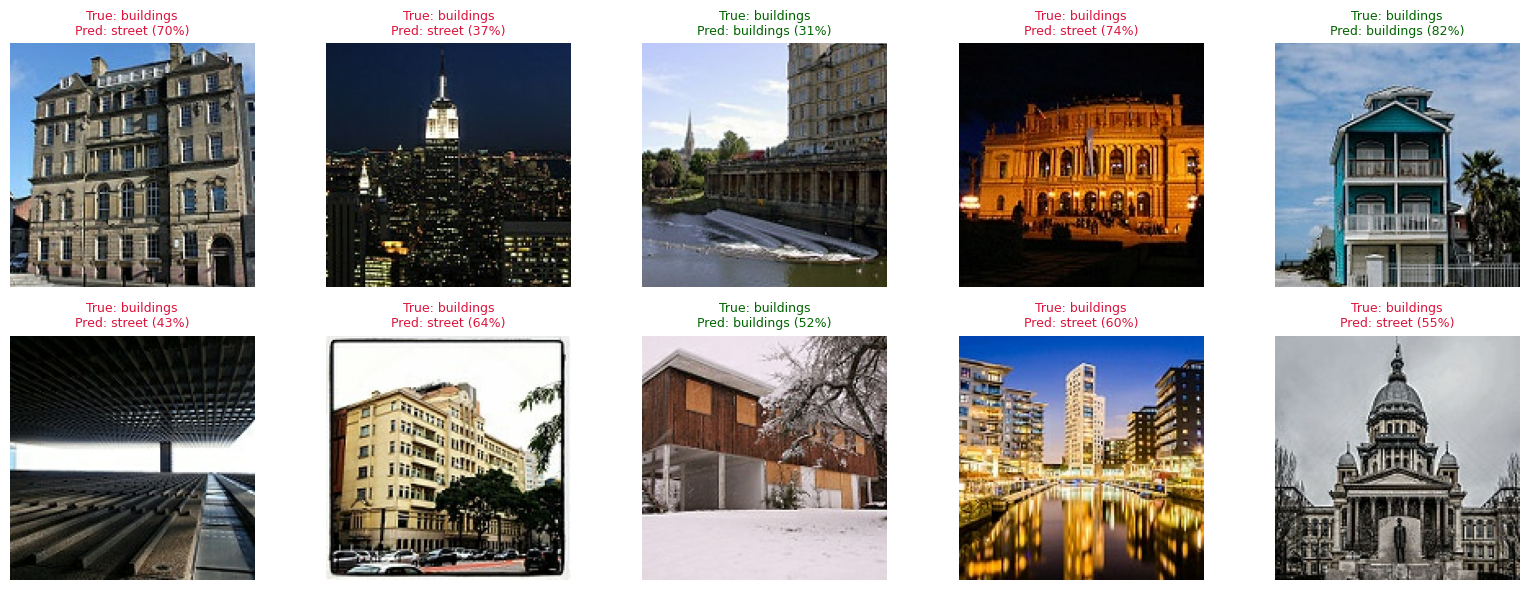

In [8]:
# Fetch unaugmented raw samples for previewing
sample_images = []
sample_labels = []

for b_imgs, b_lbls in raw_test_set.take(2):
    sample_images.extend(b_imgs.numpy().astype("uint8"))
    sample_labels.extend(np.argmax(b_lbls.numpy(), axis=1))

selected_indices = random.sample(range(len(sample_images)), 10)

plt.figure(figsize=(16, 6))
for i, idx in enumerate(selected_indices):
    raw_img = sample_images[idx]
    actual_name = label_list[sample_labels[idx]]
    
    # Scale and predict
    scaled_input = np.expand_dims(raw_img, axis=0) / 255.0
    pred = scene_classifier.predict(scaled_input, verbose=0)[0]
    pred_name = label_list[np.argmax(pred)]
    confidence = np.max(pred) * 100
    
    plt.subplot(2, 5, i + 1)
    plt.imshow(raw_img)
    is_match = (actual_name == pred_name)
    title_color = 'darkgreen' if is_match else 'crimson'
    plt.title(f"True: {actual_name}\nPred: {pred_name} ({confidence:.0f}%)", color=title_color, fontsize=9)
    plt.axis('off')

plt.tight_layout()
plt.show()